# Сгущение у всех контактов и продолжение подбора: Георг, Scorpion v2

В отчёте сопоставлены **прежняя постановка с 1×4 для записей 007–010** и **исправленная постановка с подтверждённым автором монтажом 1×1**. Рисунки обозначены отдельными последовательностями для прежнего и исправленного расчётов. Конечноэлементная модель (FEM) использует полную электродную модель (CEM) с конечными контактными площадками. Среднеквадратическая невязка обозначена RMSE, сумма квадратов ошибок — SSE; RMS обозначает среднеквадратический уровень отдельной составляющей ошибки. Система координат LPS задаёт направления влево, назад и вверх; координаты приведены в миллиметрах. Численные результаты прежнего расчёта сохранены как диагностика ранее выполненного расчёта. Глубинная геометрическая подготовка повторно используется в исправленном расчёте, а начальные электрические расчёты и подбор исправленного расчёта имеют собственные исправленные входы и подтверждённое происхождение. Ниже указано, выполнены ли контроли отдельно или повторно использованы при точно совпавшей точке.

Подтверждённый автором факт: в записях 006 и 011 все провода рук были сняты; в 007–010 использована ТТРКГ 1×1. Сохранение самих физических площадок рук остаётся допущением. При снятых проводах каждая присутствующая площадка моделируется отдельно плавающей, с нулевым внешним током. Альтернативные соединения рук в этом отчёте не проверяются.

Измеренные 24 уровня, их порядок, роли каналов и интервалы обработки между прежним и исправленным расчётами сохранены. Исправлено поле монтажа рук только для 007–010. Подтверждение соединений не является принятием дыхательной разметки: паспорт сохраняет её статус кандидата для ручного просмотра. Прибор не записывал временные метки дыхательных команд; экспертная разметка не становится непосредственно измеренным событием.

Рабочая постановка использует три удельных сопротивления — мягкотканного фона, лёгкого и жира — отдельно для вдоха и выдоха, при общем положении сборок. Материалы костей и целого сердца фиксированы. **Одна статическая КТ на глубоком вдохе используется для обеих фаз**; деформация анатомии при выдохе не моделируется. Сопоставимость состояния и положения в последовательных записях — рабочие допущения. Собственный источник задаёт выбранный расчётный сценарий; физическая фаза и отношение токов двух источников непосредственно не установлены.

## Материалы и технические границы

In [1]:
from build_georg_contact_continuation_report import load, PIPE, numbered_table, fixed_properties_table, contact_properties_table, historical_mesh_table, historical_coverage_table, historical_numerical_table, historical_numerical_figure, historical_stages_table, historical_rho_table, historical_fit_figure, historical_residual_table, historical_respiratory_figure, historical_respiratory_table, historical_contrast_contributions_table, historical_projection_table, historical_repeated_table, historical_source_table, historical_sensitivity_table, historical_sensitivity_figure, historical_conditional_figure, historical_history_figure, historical_search_table, historical_rejected_table, preparation_attempts_table, deep_quality_table, fraction_distribution_table, depth_table, depth_figure, boundary_correction_table, boundary_correction_figure, search_table, rejected_table, history_figure, rho_table, coordinate_table, span_table, historical_span_table, placement_figure, stages_table, fit_figure, residual_table, controls_levels_table, respiratory_figure, respiratory_table, contrast_contributions_table, repeated_table, sensitivity_table, sensitivity_figure, mesh_table, control_reuse_table, initial_controls_table, numerical_table, numerical_figure, coverage_table, coarse_section_figure, deep_section_figure, contact_check_table, contact_check_figure, material_update_table, body_correction_table, body_correction_figure, provenance_table
report_data=load(PIPE / 'output/exploratory/georg_confirmed_arm_continuation_20261014')

In [2]:
from IPython.display import display
display(numbered_table(fixed_properties_table(report_data),1))

Свойство или параметр,Значение или материал,Роль и допущение
Частота,100000 Гц,Частота расчётных электрических свойств
Кость,"48,0976735256 Ом·м",Фиксировано; вся маска кости представлена кортикальной костью
Целое сердце,"4,64880905755 Ом·м",Фиксировано; вся маска сердца представлена миокардом
Опорный мягкотканный фон,"2,763585998156 Ом·м",Опорное значение принято как для мышцы; сопротивление фона затем подбирается
Свободный фазовый параметр ρ1,мягкотканный фон,"Технический диапазон 0,1–100 Ом·м; индивидуальная физиологическая норма не установлена"
Свободный фазовый параметр ρ2,лёгкое,"Технический диапазон 0,1–100 Ом·м; индивидуальная физиологическая норма не установлена"
Свободный фазовый параметр ρ3,жир,"Технический диапазон 0,1–100 Ом·м; индивидуальная физиологическая норма не установлена"


In [3]:
from IPython.display import display
display(numbered_table(contact_properties_table(report_data),2))

Характеристика,Значение или диапазон,Источник и смысл
Диаметр диска,"5,0 мм",Паспорт входов: принят как допущение; не измерен
Номинальная площадь диска,"19,634954085 мм²",Геометрическая площадь π(d/2)² по принятому диаметру d
Удельный контактный импеданс: Родительская сетка,"0,000159154943091895 Ом·м²",План этой модели: фиксирован; принят как допущение; не измерен
Удельный контактный импеданс: Сгущённая сетка: унаследованные доли,"0,000159154943091895 Ом·м²",План этой модели: фиксирован; принят как допущение; не измерен
Удельный контактный импеданс: Сгущённая сетка: пересчитанные доли,"0,000159154943091895 Ом·м²",План этой модели: фиксирован; принят как допущение; не измерен
Фактическая площадь в выбранной точке,"19,646754781–20,914253307 мм²",Итоговая проверка покрытия фактических контактных граней; минимум–максимум по сохранённым описаниям
Фактическая площадь в начальной точке,"19,646754781–20,914253307 мм²",Начальный контроль контактных граней родительской сетки; минимум–максимум по сохранённым описаниям
Объём итоговой проверки,168 описаний; 10 условий записи,"Повторные описания площадок в разных условиях, без подсчёта уникальных физических электродов"
Объём начальной проверки родительской сетки,168 описаний; 10 условий записи,Сохранённая проверка контактных граней начального расчёта


Контактные площадки CEM заданы круглыми дисками принятого диаметра 5 мм; диаметр не измерен. Номинальная площадь π(d/2)² рассчитана по этому диаметру. Фактическая площадь — сумма площадей выбранных граничных граней, а не независимо измеренная площадь контакта с кожей. Диапазоны в таблице раздельно относятся к итоговой проверке покрытия выбранной точки и начальному контролю родительской сетки. Удельный контактный импеданс фиксирован в планах трёх моделей и принят как допущение, без индивидуального измерения. Сохранённые 168 описаний относятся к десяти условиям записи с повторяющимися площадками; это не 168 уникальных физических электродов и не число одновременно установленных контактов.

Фиксированные свойства кости и сердца взяты из сохранённого файла материалов глубинной модели при частоте 100000 Гц (100 кГц). Вся маска кости представлена кортикальной костью, а вся маска сердца — миокардом; кровь и миокард внутри неё отдельно не моделируются. Это модельные допущения, а не независимые индивидуальные референсы. Количественное влияние этих фиксированных свойств не устанавливается без отдельных производных по ним.

Опорное сопротивление мягкотканного фона принято как для мышцы. При этом фон объединяет весь объём модели вне масок лёгкого, кости, сердца и жира; мышечное опорное значение не подтверждает однородности этого объёма. Свободные фазовые параметры имеют индексы 1 — мягкотканный фон, 2 — лёгкое, 3 — жир; в полном порядке пяти материалов им соответствуют позиции 1, 2 и 5. Они подбираются отдельно для вдоха и выдоха. Диапазон 0,1–100 Ом·м является технической областью поиска, а не физиологической нормой; индивидуальные сопротивления тканей не измерены независимо.

Все рисунки имеют самостоятельные средства просмотра и отключения рядов. Трёхмерный рисунок сохраняет камеру при переключении легенды. Таблицы раскрываются отдельно. Линии между номерами наблюдений служат сравнению дискретных записей и не являются временной интерполяцией.

## Прежняя постановка с 1×4: диагностика граничных условий

Исходный совместный лимит был 80 оценок: 23 начатые оценки первой попытки сохранены отдельно, затем для прежнего расчёта выделены 57. Это история исходного лимита; она не включает новую квоту исправленного расчёта. Старый фиксированный профиль при прежнем центре завершился с сохранённым числом 15 вычислений целевой функции и RMSE **14,3879589 Ом**. По сохранённым сведениям о длительности он занял около 94 минут, а поиск с лимитом 57 — около 215 минут; эти длительности описывают ресурсное ограничение, а не математическую сходимость.

Для старого продолжения одновременно менялись технические границы сопротивлений до 0,1–100 Ом·м и способ оптимизации. Снижение невязки относительно прежней постановки не устанавливает причинного эффекта оптимизатора отдельно от расширения границ. Эти пределы не являются индивидуально валидированными физиологическими нормами. Представление `exp(log(100)) = 100.00000000000004` отличается от 100 только округлением арифметики с плавающей точкой; оно не означает расширения технической границы. Числа в сохранённых результатах не подменяются. Для читательской отметки близости к техническим границам 0,1 и 100 Ом·м принят абсолютный допуск 10⁻⁶ Ом·м без относительного допуска. Он используется только в подписи таблицы: параметры, их границы и результаты расчётов не изменяются. Попадание параметра на границу не даёт его двусторонней оценки или доверительного интервала.

In [4]:
from IPython.display import display
display(numbered_table(historical_mesh_table(report_data),3))

Сетка,Узлы,Тетраэдры,Минимальный показатель формы,Максимальная обусловленность рёбер,Контроль пройден
Базовая,605 573,2 950 272,"0,011517","619,3",Да
Локально сгущённая,826 136,4 157 156,"0,011517","619,3",Да


In [5]:
from IPython.display import display
display(numbered_table(historical_coverage_table(report_data),4))

Условия,Запись,Площадок,Полностью покрыто,"Минимальная доля площади, %"
Перед подбором,002,16,16,"100,00"
Перед подбором,003,16,16,"100,00"
Перед подбором,004,16,16,"100,00"
Перед подбором,005,16,16,"100,00"
Перед подбором,006,20,20,"100,00"
Перед подбором,007,16,16,"100,00"
Перед подбором,008,16,16,"100,00"
Перед подбором,009,16,16,"100,00"
Перед подбором,010,16,16,"100,00"
Перед подбором,011,20,20,"100,00"


In [6]:
from IPython.display import display
display(numbered_table(historical_numerical_table(report_data),5))

Условия,Изменение,"Максимум |ΔZ|, Ом",Превышения из 24,Максимум |ΔZ|/допуск
Прежний расчёт: прежние параметры и положение,Пространство FEM,"0,10977",0,"0,2058"
Прежний расчёт: прежние параметры и положение,Тканевые доли,"0,25978",0,"0,4415"
Прежний расчёт: прежние параметры и положение,Суммарное изменение,"0,34818",0,"0,5665"
Новый выбранный кандидат,Пространство FEM,"0,45010",0,"0,8570"
Новый выбранный кандидат,Тканевые доли,"0,23702",0,"0,5369"
Новый выбранный кандидат,Суммарное изменение,"0,57801",6,"1,2610"


In [7]:
from IPython.display import display
display(historical_numerical_figure(report_data,include_js=True))

**Рисунок прежнего расчёта 1. Численные контроли выбранной точки прежнего расчёта.** Синие столбцы — изменение пространства FEM при точном наследовании долей; оранжевые — повторное интегрирование масок на той же сетке; фиолетовые — суммарное изменение родитель → сгущённая сетка с пересчитанными долями. Высота — |ΔZ|, делённое на сохранённый допуск 0,02 + 0,005|Z правого расчёта| Ом. Чёрный пунктир на уровне 1 — граница допуска. Параметры и координаты в тройке фиксированы, без новой оптимизации. Итоговые допуски прежнего расчёта **выдержаны не все**; завершение процедуры само по себе не разрешает количественную интерпретацию.

In [8]:
from IPython.display import display
display(numbered_table(historical_stages_table(report_data),6))

Этап,"RMSE, Ом","Ошибка средних уровней, Ом","Ошибка половины контраста, Ом","Доля контраста в SSE, %"
Прежний расчёт: прежний кандидат,"27,6352","27,4544","3,1565","1,3046"
"Прежний расчёт: новая сетка, прежние параметры","27,6161","27,4355","3,1527","1,3033"
Прежний расчёт: фиксированный центр,"14,3880","14,3595","0,9038","0,3946"
Прежний расчёт: совместный подбор,"13,6757","13,6458","0,9039","0,4369"


In [9]:
from IPython.display import display
display(numbered_table(historical_rho_table(report_data),7))

Этап,Материал,"Вдох, Ом·м","Выдох, Ом·м",Близость к техническому пределу (≤10⁻⁶ Ом·м)
Прежний расчёт: прежний кандидат,Мягкотканный фон,"2,308341","2,763586",Нет
Прежний расчёт: прежний кандидат,Лёгкое,"9,315253","9,315253",Нет
Прежний расчёт: прежний кандидат,Жир,"12,644952","12,644952",Нет
Прежний расчёт: фиксированный центр,Мягкотканный фон,"0,829141","0,829930",Нет
Прежний расчёт: фиксированный центр,Лёгкое,"100,000000","100,000000",Да
Прежний расчёт: фиксированный центр,Жир,"100,000000","100,000000",Да
Прежний расчёт: совместный подбор,Мягкотканный фон,"0,829141","0,829930",Нет
Прежний расчёт: совместный подбор,Лёгкое,"100,000000","100,000000",Да
Прежний расчёт: совместный подбор,Жир,"100,000000","100,000000",Да


In [10]:
from IPython.display import display
display(historical_fit_figure(report_data,include_js=False))

**Рисунок прежнего расчёта 2. Все уровни при ошибочных граничных условиях.** Красные ряды — вдох, сине-зелёные — выдох; пунктир и круги — измерение, сплошная линия и квадраты — модель. По горизонтали — запись, размер и ось сборки. RMSE выбранной точки прежнего расчёта равна **13,6757423 Ом**.

In [11]:
from IPython.display import display
display(numbered_table(historical_residual_table(report_data),8))

Запись,"Размер, мм",Канал,Ось,Состояние,"Измерено, Ом","Рассчитано, Ом","Модель минус измерение, Ом","Относительная невязка, %"
002,140,2,Продольная,Вдох,"79,427","76,245","-3,182","-4,0"
002,140,2,Продольная,Выдох,"79,412","76,301","-3,111","-3,9"
003,140,2,Продольная,Вдох,"80,953","76,227","-4,727","-5,8"
003,140,2,Продольная,Выдох,"80,507","76,282","-4,225","-5,2"
004,140,2,Продольная,Вдох,"79,595","76,221","-3,375","-4,2"
004,140,2,Продольная,Выдох,"79,095","76,277","-2,819","-3,6"
005,140,2,Поперечная,Вдох,"75,980","84,230","8,250","10,9"
005,140,2,Поперечная,Выдох,"80,802","84,291","3,489","4,3"
006,140,1,Продольная,Вдох,"76,818","76,162","-0,656","-0,9"
006,140,1,Продольная,Выдох,"75,932","76,218","0,286","0,4"


In [12]:
from IPython.display import display
display(historical_respiratory_figure(report_data,include_js=False))

**Рисунок прежнего расчёта 3. Контраст ΔZ = Z выдоха − Z вдоха.** Чёрные круги — измерение; серые квадраты — прежний кандидат; синие — новая поверхностная сетка с прежними параметрами; фиолетовые — фиксированный профиль; оранжевые — совместный кандидат прежнего расчёта. Чёрный пунктир — нулевой контраст. Знак не совпадает в **8 из 12 пар** для выбранной точки прежнего расчёта с ошибочными граничными условиями.

In [13]:
from IPython.display import display
display(numbered_table(historical_respiratory_table(report_data),9))

Запись и ось,"Эксперимент, Ом","Прежний расчёт: прежний кандидат, Ом","Прежний расчёт: новая сетка, прежние параметры, Ом","Прежний расчёт: фиксированный центр, Ом","Прежний расчёт: совместный подбор, Ом"
002 · продольная,"-0,0149","3,2926","3,2914","0,0544","0,0560"
003 · продольная,"-0,4463","3,2923","3,2911","0,0544","0,0560"
004 · продольная,"-0,5002","3,2922","3,2910","0,0544","0,0559"
005 · поперечная,"4,8222","3,5473","3,5389","0,0621","0,0613"
006 · продольная,"-0,8855","3,2927","3,2915","0,0544","0,0559"
006 · поперечная,"2,5709","3,5479","3,5395","0,0620","0,0613"
007 · продольная,"-0,4810","3,8316","3,8308","0,0633","0,0648"
008 · продольная,"0,0796","4,8283","4,8278","0,0729","0,0731"
009 · продольная,"-1,8556","6,5256","6,5410","0,0820","0,0814"
010 · продольная,"0,9958","9,5421","9,5329","0,0882","0,0892"


In [14]:
from IPython.display import display
display(numbered_table(historical_contrast_contributions_table(report_data),10))

Результат,Материал,ln(ρ выдоха / ρ вдоха),"Минимальный вклад, Ом","Максимальный вклад, Ом","Максимальная ошибка суммы вкладов, Ом"
Фиксированный центр прежнего расчёта,Фон,"0,0009508803","0,05435201","0,08898929","0,00000000"
Фиксированный центр прежнего расчёта,Лёгкое,"0,0000000000","0,00000000","0,00000000","0,00000000"
Фиксированный центр прежнего расчёта,Жир,"0,0000000002","0,00000000","0,00000000","0,00000000"
Совместный подбор прежнего расчёта,Фон,"0,0009508803","0,05590351","0,08921541","0,00000000"
Совместный подбор прежнего расчёта,Лёгкое,"0,0000000000","0,00000000","0,00000000","0,00000000"
Совместный подбор прежнего расчёта,Жир,"0,0000000000","0,00000000","0,00000000","0,00000000"


In [15]:
from IPython.display import display
display(numbered_table(historical_projection_table(report_data),11))

Характеристика,Результат
Формальная поправка к разности логарифмов: фон; лёгкое; жир,"-0,064936; -251,799858; 0,630255"
"Сингулярные числа матрицы H, Ом","260,003002; 21,391481; 0,017069"
Отношение крайних сингулярных чисел,"15232,49"
"RMS остаточного контраста, Ом","1,073364"
"Доля необъяснённой суммы квадратов контраста, %","35,205"
Несовпадения знака из 12,2
Допустимость найденной поправки,Вне области локального приближения и технических пределов


Индексы $i$ и $e$ обозначают вдох и выдох соответственно; верхние индексы $model$ и $obs$ — модель и наблюдение. Для ошибок пары $e_i=Z_i^{model}-Z_i^{obs}$, $e_e=Z_e^{model}-Z_e^{obs}$ введены $a=(e_i+e_e)/2$ и $b=(e_e-e_i)/2$. Тогда $RMSE^2=mean_{12}(a^2)+mean_{12}(b^2)$. Для выбранной точки прежнего расчёта RMS ошибки среднего уровня равна **13,645837 Ом**, RMS ошибки половины контраста — **0,903912 Ом**; вклад последней в SSE — **0,4369 %**. Абсолютные уровни и парный дыхательный контраст анализируются отдельно.

Локальная проекция относится только к **старому фиксированному профилю прежнего расчёта**. Для каждой пары $H=(J_{i,\rho_i}+J_{e,\rho_e})/2$, столбцы — производные по логарифмам трёх сопротивлений. Использована фактическая модельная разность $\Delta Z_0$ и формальная поправка $\eta=\arg\min\|H\eta-(\Delta Z_{obs}-\Delta Z_0)\|^2$. Проекция — $\Delta Z_0+H\eta$; остаток — проекция минус измеренный контраст. RMS остатка равна **1,073364 Ом**. Большой логарифмический шаг выходит из области локального приближения; формальный результат не является новым физическим решением. Локальный якобиан не доказывает глобальной несовместимости общего состояния и не переносится автоматически на новый центр исправленного расчёта.

In [16]:
from IPython.display import display
display(numbered_table(historical_repeated_table(report_data),12))

Повтор,Состояние,Ряд,"Отдельная запись, Ом","Запись креста, Ом","Крест минус отдельная запись, Ом"
140 мм поперечная: 005 → 006,Вдох,Эксперимент,"75,9798","81,5149","5,5351"
140 мм поперечная: 005 → 006,Вдох,Прежний расчёт: прежний кандидат,"57,3765","57,3657","-0,0108"
140 мм поперечная: 005 → 006,Вдох,"Прежний расчёт: новая сетка, прежние параметры","57,4477","57,4369","-0,0108"
140 мм поперечная: 005 → 006,Вдох,Прежний расчёт: фиксированный центр,"84,9943","84,9150","-0,0793"
140 мм поперечная: 005 → 006,Вдох,Прежний расчёт: совместный подбор,"84,2296","84,1429","-0,0867"
140 мм поперечная: 005 → 006,Выдох,Эксперимент,"80,8021","84,0859","3,2838"
140 мм поперечная: 005 → 006,Выдох,Прежний расчёт: прежний кандидат,"60,9238","60,9136","-0,0102"
140 мм поперечная: 005 → 006,Выдох,"Прежний расчёт: новая сетка, прежние параметры","60,9866","60,9764","-0,0102"
140 мм поперечная: 005 → 006,Выдох,Прежний расчёт: фиксированный центр,"85,0564","84,9770","-0,0794"
140 мм поперечная: 005 → 006,Выдох,Прежний расчёт: совместный подбор,"84,2910","84,2042","-0,0867"


In [17]:
from IPython.display import display
display(numbered_table(historical_source_table(report_data),13))

Условия возбуждения,Коэффициент α,"RMSE, Ом",Несовпадения знака из 12
Собственный источник,0,"13,6757",8
"Равные токи, совпадающая фаза",1,"15,3652",8
"Равные токи, противоположные фазы",−1,"13,0846",8
"Равные токи, 90° и модуль",Неприменимо,"13,6487",8
Условный вещественный подбор доли второго источника,"-0,97578","13,0843",8


Повторные 005 → 006 и 010 → 011 сохраняют боковую сборку, но меняют подключение соседних рук и условия регистрации. Разность в таблице — запись креста минус отдельная запись, отдельно для обеих фаз. Она проверяет совместимость предположения об общем состоянии с конкретной схемой возбуждения, без доказательства дрейфа, аппаратной неисправности или иной причины. Сценарии источников вычислены из сохранённых векторов передаточного импеданса при тех же параметрах: α = 0, +1, −1; 90° показаны как $\sqrt{Z_1^2+Z_2^2}$, где $Z_1$ и $Z_2$ — вклады собственного и встречного источников. Это модуль при принятой квадратуре. Ограниченный вещественный α — только диагностическая проекция. Ни один сценарий не устанавливает реальную фазу или способ регистрации сигнала прибора.

In [18]:
from IPython.display import display
display(numbered_table(historical_sensitivity_table(report_data),14))

Номер,"Сингулярное число, Ом"
1,"261,230362"
2,"261,042947"
3,"21,380215"
4,"21,353667"
5,"0,013849"
6,"0,013821"


In [19]:
from IPython.display import display
display(historical_sensitivity_figure(report_data,include_js=False))

**Рисунок прежнего расчёта 4. Якобиан шести логарифмов ρ.** Цвет ячейки — знаковая производная импеданса, Ом, по логарифму параметра; строки — 24 наблюдения, столбцы — три материала отдельно для вдоха и выдоха. Сингулярные числа характеризуют локальную информативность этой точки, без экспериментальной валидации или полного анализа положения.

In [20]:
from IPython.display import display
display(historical_conditional_figure(report_data,include_js=False))

**Рисунок прежнего расчёта 5. Сохранённые однопараметрические пробы.** Круги — вдох, ромбы — выдох; цвет и название ряда указывают материал. По горизонтали — изменяемое ρ в логарифмической шкале, по вертикали — RMSE 24 уровней. Включены только пробы, у которых остальные восемь параметров совпадают с началом старого совместного поиска. Это не завершённые профили правдоподобия.

In [21]:
from IPython.display import display
display(historical_history_figure(report_data,include_js=False))

**Рисунок прежнего расчёта 6. Ход поиска.** Серые точки — рассчитанные кандидаты, синяя линия — лучший достигнутый RMSE. Зелёные открытые ромбы, если присутствуют, — свежие проверки после поиска; красные кресты — отказ геометрии на условной высоте максимального рассчитанного RMSE, без собственного значения целевой функции. Номер оценки не является временем или номером независимого опыта.

In [22]:
from IPython.display import display
display(numbered_table(historical_search_table(report_data),15))

Характеристика,Результат
Прежний расчёт: исходный суммарный предел,80
Прежний расчёт: начатые оценки первой остановленной попытки,23
Прежний расчёт: выделенный остаток исходного лимита,57
"Завершённые оценки поиска, включая отказы",57
Отказы контактов/геометрии внутри поиска,8
Свежие проверки кандидата после поиска,1
Начатые оценки без результата,0
Остановка по времени,Не отмечена в сохранённом результате
Остановка по квоте,Да
Полные обходы направлений,4


In [23]:
from IPython.display import display
display(numbered_table(historical_rejected_table(report_data),16))

Оценка,"Первое смещение, мм","Второе смещение, мм","Угол, °",Основание отказа,"Максимальная ошибка площади, %","Максимальное смещение центроида, мм","Максимальная протяжённость, мм"
10,"-20,000","0,000","0,000",Нарушен допуск дискретной площадки,"25,122","0,338","3,724"
12,"-10,000","-10,000","0,000",Нарушен допуск дискретной площадки,"2,855","0,598","4,319"
15,"-10,000","0,000","5,000",Нарушен допуск дискретной площадки,"19,488","0,498","3,675"
38,"-15,000","-5,000","0,000",Нарушен допуск дискретной площадки,"6,355","0,409","3,975"
50,"-15,000","-5,000","-2,500",Нарушен допуск дискретной площадки,"6,336","0,360","3,928"
51,"-5,000","-5,000","-2,500",Нарушен допуск дискретной площадки,"23,140","0,608","3,903"
52,"-10,000","-10,000","-2,500",Нарушен допуск дискретной площадки,"21,138","0,699","3,711"
53,"-10,000","-5,000","-5,000",Нарушен допуск дискретной площадки,"13,918","0,419","3,248"


## Подготовка глубинной сетки и остановленные проверки прежнего расчёта

Первая подготовка глубинной сетки завершилась **отказом по качеству**: минимум показателя формы в трёх сохранённых попытках оказался ниже 0,01. Лимиты не ослаблялись. Следующая подготовка дала пригодную по форме сетку с **860255 узлами и 4356504 тетраэдрами**, минимум безразмерного показателя формы **0,011516966**. Её геометрия и доли использованы как входы исправленного расчёта.

In [24]:
from IPython.display import display
display(numbered_table(preparation_attempts_table(report_data),17))

Ветвь,Попытка,Узлы,Тетраэдры,Минимальный безразмерный показатель формы,Нарушений формы,Контроль формы
Первая подготовка: отказ,0,860187,4356117,"0,009639356",2,Нет
Первая подготовка: отказ,1,860209,4356231,"0,007725355",5,Нет
Первая подготовка: отказ,2,860251,4356481,"0,005865243",1,Нет
Вторая подготовка: завершена,Итог,860255,4356504,"0,011516966",0,Да


In [25]:
from IPython.display import display
display(numbered_table(deep_quality_table(report_data),18))

Характеристика,Результат
Узлы,860255
Тетраэдры,4356504
Минимальный показатель формы,"0,011516966"
Максимальная обусловленность матрицы рёбер,"619,300"
Нарушения допуска формы,0
Нарушения допуска обусловленности рёбер,0
Все ориентированные объёмы положительны,Да
Относительное изменение общего объёма,"0,000000000000"
FEM-контроли прежних граничных условий после второй подготовки,Остановлены; завершённая проверка не заявляется


Дальнейшие электрические проверки прежней постановки остановлены после уточнения автором монтажа рук. Отсутствующие проверки глубинного сгущения и непосредственного выбора контактных граней в прежней постановке не трактуются как пройденные и не требуются для чтения подготовки. Качество формы, положительные объёмы и наследование геометрии не устанавливают достаточности FEM-дискретизации: это отдельные численные сравнения исправленного расчёта ниже.

In [26]:
from IPython.display import display
display(numbered_table(fraction_distribution_table(report_data),19))

Сетка,Проб на элемент,Изменена хотя бы одна доля,Материал,Элементов с изменением,Максимум |Δдоля|
Прежний расчёт: поверхностное уточнение,1024,134369,Мягкотканный фон,134369,"0,860352"
Прежний расчёт: поверхностное уточнение,1024,134369,Лёгкое,0,"0,000000"
Прежний расчёт: поверхностное уточнение,1024,134369,Кость,0,"0,000000"
Прежний расчёт: поверхностное уточнение,1024,134369,Целое сердце,0,"0,000000"
Прежний расчёт: поверхностное уточнение,1024,134369,Жир,134369,"0,860352"
Прежний расчёт: поверхностное уточнение,4096,137129,Мягкотканный фон,137129,"0,860596"
Прежний расчёт: поверхностное уточнение,4096,137129,Лёгкое,0,"0,000000"
Прежний расчёт: поверхностное уточнение,4096,137129,Кость,0,"0,000000"
Прежний расчёт: поверхностное уточнение,4096,137129,Целое сердце,0,"0,000000"
Прежний расчёт: поверхностное уточнение,4096,137129,Жир,137129,"0,860596"


На поверхностной сетке прежнего расчёта при 4096 пробах изменились доли в **137129** элементах; изменения затрагивали фон и жир, без изменений лёгкого, костей и сердца. Этот узкий охват нельзя переносить на глубинную сетку: здесь изменены **184743** элементов, в том числе лёгкое — **11704**, кость — **11358**, фон — **184705**, жир — **169778**; целое сердце — **0**. Счётчики по материалам пересекаются и не суммируются как независимые элементы. Доли сравниваются на одной объёмной сетке, без изменения координат. Это дискретизация состава тканей, без электрического разложения вкладов компартментов и без независимой проверки сегментации.

In [27]:
from IPython.display import display
display(numbered_table(depth_table(report_data),20))

"Размер, мм",Ось,Контакт,"Первое попадание в маску лёгкого, мм","Смещение начала при проекции, мм"
60,Продольная,I+,"59,5","0,000000"
60,Продольная,U+,"64,5","0,000000"
60,Продольная,U-,"73,5","0,000000"
60,Продольная,I-,"78,5","0,000000"
80,Продольная,I+,"58,0","0,000000"
80,Продольная,U+,"62,0","0,000000"
80,Продольная,U-,"74,0","0,000000"
80,Продольная,I-,Нет на первых 80 мм,"0,000000"
100,Продольная,I+,"48,5","0,000000"
100,Продольная,U+,"64,0","0,000000"


In [28]:
from IPython.display import display
display(depth_figure(report_data,include_js=False))

**Рисунок прежнего расчёта 7. КТ-профили старого положения прежнего расчёта.** Квадраты обозначают материал проб вдоль принятой внутренней нормали: бежевый — фон, синий — лёгкое, серый — кость, красный — целое сердце, жёлтый — жир, чёрный — вне поля КТ. Открытый ромб — первое попадание в маску лёгкого. Из 28 лучей в 24 лёгкое найдено на глубине 38,0–79,0 мм; для остальных нет попадания на первых 80 мм. Это не отсутствие лёгкого во всём чувствительном объёме. Лучи относятся к подготовке при прежних координатах прежнего расчёта; при изменении позы исправленного расчёта они не переименовываются в новые итоговые КТ-профили. Геометрическое сгущение по лучам не является картой электрической чувствительности.


## Исправленная постановка с 1×1: изолированный эффект исправления граничных условий

Перед новым поиском повторён расчёт на **том же родителе**, при точно тех же ρ и позе, что в выбранной точке прежнего расчёта. Сопоставлены выбранный расчёт прежней постановки на родительской сетке и начальный расчёт исправленной постановки на той же сетке; используется сохранённый результат 4096 проб. Маски, объёмная сетка, исходный каталог физических контактов и числовые наблюдения совпадают. Единственное изменённое поле входов — 1×4 → 1×1 для 007–010; условия раздельно плавающих площадок при крестах уже использовались в старом расчёте.

In [29]:
from IPython.display import display
display(numbered_table(boundary_correction_table(report_data),21))

Наблюдение,Изменён монтаж 007–010,"Прежний расчёт, Ом","Исправленный расчёт, Ом","исправленный расчёт минус прежний, Ом","Модуль изменения, Ом"
002 · продольная · вдох,Нет,"76,0677116219","76,0677116219","0,0000000000","0,0000000000"
002 · продольная · выдох,Нет,"76,1235160476","76,1235160476","0,0000000000","0,0000000000"
003 · продольная · вдох,Нет,"76,0484732680","76,0484732680","0,0000000000","0,0000000000"
003 · продольная · выдох,Нет,"76,1042670876","76,1042670876","0,0000000000","0,0000000000"
004 · продольная · вдох,Нет,"76,0423700123","76,0423700123","0,0000000000","0,0000000000"
004 · продольная · выдох,Нет,"76,0981601550","76,0981601550","0,0000000000","0,0000000000"
005 · поперечная · вдох,Нет,"83,6758144059","83,6758144059","0,0000000000","0,0000000000"
005 · поперечная · выдох,Нет,"83,7367100592","83,7367100592","0,0000000000","0,0000000000"
006 · продольная · вдох,Нет,"75,9744499510","75,9744499510","0,0000000000","0,0000000000"
006 · продольная · выдох,Нет,"76,0301852062","76,0301852062","0,0000000000","0,0000000000"


In [30]:
from IPython.display import display
display(boundary_correction_figure(report_data,include_js=False))

**Рисунок исправленного расчёта 1. Исправление соединений на неизменном родителе.** Синие круги показывают знаковую разность исправленного и прежнего расчётов, оранжевые квадраты — её модуль; чёрный пунктир — нулевое изменение. Каждый ряд отключается независимо. Максимум модуля изменения — **0,0182109394 Ом**. Для остальных 16 наблюдений максимум — **0,000000000000 Ом**; проверка ≤10⁻⁸ Ом **пройдена**. RMSE на фиксированном родителе изменяется **13,6419005421 → 13,6404410790 Ом**.

Это изолирует влияние подтверждённых граничных условий от глубинного сгущения и оптимизации. Само исправление соединений в этой точке не объясняет большую остаточную невязку собственного источника. Оно не доказывает ошибку прибора: реальные фазы и токи не установлены. Разность итоговых RMSE прежнего и исправленного расчётов включает другие изменения и не является изолированным эффектом граничных условий.

## Исправленная постановка с 1×1: самостоятельный ограниченный совместный поиск

Для соблюдения исходного срока профиль сопротивлений при фиксированном центре пропущен **до выполнения**. Исходная конфигурация сохранена отдельно; её план профиля не выдается за исполненную стадию. Унаследованные сведения о лимитах 80 и 23 оценок и прежнем начальном приближении относятся к истории расчётов. Три начальных контроля завершены до смены порядка и сохранены с их прежними сведениями о происхождении; они не переименовываются в новые расчёты. Новый поиск запущен из того же сохранённого начального приближения исправленного расчёта. Порядок проверок исходных параметров теперь [7, 8, 9, 1, 4, 2, 5, 3, 6]: сначала два смещения центра и угол, затем сопротивления фона, лёгкого и жира для обеих фаз. Дополнительная настройка порядка проверок возвращает физические параметры в исходную последовательность; порядок по умолчанию от 1 до 9 сохранён. Исполненная до изменения порядка версия обратного расчёта сохранена в архиве и проверяется по прежней контрольной сумме. Уравнения, границы сопротивлений тканей и физическое ядро не изменялись.

Параметры прежнего расчёта перенесены только как начальное приближение. Старые предсказания и сведения о происхождении подгонки не перенесены. Первый ряд исправленного расчёта в таблицах — свежий контроль с пересчитанными долями этого приближения на глубинной сетке. Первоначальное число совместных оценок, выделенных исправленному расчёту, — **24**. Перед изменением приоритета в заменённой попытке совместного поиска без предварительного профиля число начатых оценок — **1**; готовых численных промежуточных результатов — **0**. Предельное число оценок поиска с приоритетом геометрии — **23**, при прежних сроках остановки поиска и всей задачи. Начатая без результата оценка не считается готовым кандидатом и не прибавляется к завершённым оценкам поиска с приоритетом геометрии. Число фактически завершённых оценок, включая отказы, — **4**; достижение целевого разрешения **не подтверждено**. Готовых численных кандидатов — **3**, геометрических отказов — **1**, начатых оценок без численного результата — **1**. Новых готовых кандидатов с изменением ρ — **0**, с изменением угла — **0**. Поэтому объявленный приоритет геометрии не означает выполненного обхода всех геометрических направлений или новых материальных проб. Поиск ограничен временем и числом оценок; выбранный кандидат не объявляется полным оптимумом или доказательством глобальной неидентифицируемости.

In [31]:
from IPython.display import display
display(numbered_table(search_table(report_data),22))

Характеристика,Результат
Исправленный расчёт: первоначальная отдельная квота,24
Исправленный расчёт: начатые оценки заменённой попытки совместного поиска без предварительного профиля,1
Исправленный расчёт: готовые численные промежуточные результаты заменённого запуска,0
Исправленный расчёт: незавершённые оценки заменённого запуска,1
Исправленный расчёт: предел нового поиска с приоритетом геометрии,23
Исправленный расчёт: порядок проверки параметров (исходные индексы 1–9),"7, 8, 9, 1, 4, 2, 5, 3, 6"
Исправленный расчёт: фиксированный профиль,Пропущен до выполнения из-за исходного лимита времени
"Завершённые оценки поиска, включая отказы",4
Отказы контактов/геометрии внутри поиска,1
Свежие проверки кандидата после поиска,0


In [32]:
from IPython.display import display
display(numbered_table(rejected_table(report_data),23))

Оценка,"Первое смещение, мм","Второе смещение, мм","Угол, °",Основание отказа,"Максимальная ошибка площади, %","Максимальное смещение центроида, мм","Максимальная протяжённость, мм"
4,"-10,000","-15,000","-2,500",Нарушен допуск дискретной площадки,"20,709","0,582","3,875"


In [33]:
from IPython.display import display
display(history_figure(report_data,include_js=False))

**Рисунок исправленного расчёта 2. Новый поиск.** Серые точки — RMSE рассчитанных кандидатов, синяя линия — лучшее достигнутое значение. Зелёные открытые ромбы, если присутствуют, — свежие проверки после поиска. Красные кресты — отказ геометрии на условном уровне, без вычисленной RMSE. Небольшой доступный объём поиска ограничивает выводы даже при улучшении невязки.

In [34]:
from IPython.display import display
display(numbered_table(rho_table(report_data),24))

Этап,Материал,"Вдох, Ом·м","Выдох, Ом·м",Близость к техническому пределу (≤10⁻⁶ Ом·м)
Исправленный расчёт: только начальное приближение,Мягкотканный фон,"0,829141","0,829930",Нет
Исправленный расчёт: только начальное приближение,Лёгкое,"100,000000","100,000000",Да
Исправленный расчёт: только начальное приближение,Жир,"100,000000","100,000000",Да
Исправленный расчёт: выбранный кандидат,Мягкотканный фон,"0,829141","0,829930",Нет
Исправленный расчёт: выбранный кандидат,Лёгкое,"100,000000","100,000000",Да
Исправленный расчёт: выбранный кандидат,Жир,"100,000000","100,000000",Да


In [35]:
from IPython.display import display
display(numbered_table(coordinate_table(report_data),25))

"Размер, мм",Ось,Контакт,"x LPS, мм","y LPS, мм","z LPS, мм"
60,Продольная,I+,"-196,74","-22,10","-246,85"
60,Продольная,U+,"-199,10","-23,41","-232,10"
60,Продольная,U−,"-202,72","-25,67","-202,44"
60,Продольная,I−,"-204,07","-26,75","-187,53"
80,Продольная,I+,"-194,85","-21,11","-256,62"
80,Продольная,U+,"-198,39","-22,94","-237,05"
80,Продольная,U−,"-203,05","-25,96","-197,59"
80,Продольная,I−,"-205,25","-27,54","-177,63"
100,Продольная,I+,"-192,86","-20,12","-266,38"
100,Продольная,U+,"-197,33","-22,47","-241,90"


In [36]:
from IPython.display import display
display(numbered_table(span_table(report_data),26))

"Номинальный размер, мм",Ось,"I+ → I−, хорда, мм","U+ → U−, хорда, мм"
60,Продольная,"59,953179","29,968759"
80,Продольная,"79,925258","39,842049"
100,Продольная,"99,841053","49,909271"
120,Продольная,"119,909160","59,953179"
140,Продольная,"139,806111","69,821094"
60,Поперечная,"57,777416","29,610137"
140,Поперечная,"124,700525","66,613228"


In [37]:
from IPython.display import display
display(numbered_table(historical_span_table(report_data),27))

"Номинальный размер, мм",Ось,"I+ → I−, хорда, мм","U+ → U−, хорда, мм"
60,Продольная,"59,953179","29,968759"
80,Продольная,"79,925258","39,842049"
100,Продольная,"99,841053","49,909271"
120,Продольная,"119,909160","59,953179"
140,Продольная,"139,806111","69,821094"
60,Поперечная,"57,777416","29,610137"
140,Поперечная,"124,700525","66,613228"


Расстояния между I+ и I−, U+ и U− рассчитаны непосредственно из сохранённых итоговых координат каждой постановки. Это **хорды после проекции**, без измерения поверхностной дуги. В расчёте положения использован метод Ника: смещения в касательной плоскости с последующей проекцией на треугольную поверхность. Номинальное расстояние в этой конструкции не задаёт геодезическую длину по поверхности. На кривой коже хорда может быть короче поверхностной дуги; её уменьшение само по себе не является доказанной ошибкой. Физический смысл номинального расстояния и его связь с геодезической длиной носителя требуют отдельной проверки.

In [38]:
from IPython.display import display
display(placement_figure(report_data,include_js=False))

**Рисунок исправленного расчёта 3. Итоговое расчётное положение.** Наружный контур полупрозрачен; маски тканей включаются через легенду и подписаны по материалам. Оранжевые ряды — продольные сборки, сине-зелёные — поперечные; круги — I+, I−, квадраты — U+, U−. Линии соединяют центры для отображения расположения, без утверждения о физическом соединении площадок. Фиолетовые точки — постоянные площадки рук (их присутствие — допущение), коричневый крест — исходная ориентировочная точка автора, малиновый ромб — найденный общий центр. Поверхности упрощены для отображения; рисунок не подменяет фактические FEM-грани контактов. Выбранный центр LPS, мм: **[-201,0467; -24,5786; -217,2678]**. Ракурс и масштаб сохраняются при отключении рядов.

In [39]:
from IPython.display import display
display(numbered_table(stages_table(report_data),28))

Этап,"RMSE, Ом","Ошибка средних уровней, Ом","Ошибка половины контраста, Ом","Доля контраста в SSE, %"
Исправленный расчёт: свежий контроль с пересчитанными долями начального приближения,"13,6827","13,6528","0,9039","0,4364"
Исправленный расчёт: выбранный кандидат ограниченного совместного поиска,"13,6827","13,6528","0,9039","0,4364"


In [40]:
from IPython.display import display
display(fit_figure(report_data,include_js=False))

**Рисунок исправленного расчёта 4. Все 24 уровня.** Красные ряды — вдох, сине-зелёные — выдох. Пунктир с кругами — эксперимент; сплошные линии с квадратами — модель исправленного расчёта. По горизонтали — записи, размеры и оси. RMSE выбранного кандидата — **13,6826738 Ом**; тканевые параметры не приняты как индивидуально валидированные значения.

In [41]:
from IPython.display import display
display(numbered_table(residual_table(report_data),29))

Запись,"Размер, мм",Канал,Ось,Состояние,"Измерено, Ом","Рассчитано, Ом","Модель минус измерение, Ом","Относительная невязка, %"
002,140,2,Продольная,Вдох,"79,427","76,600","-2,827","-3,6"
002,140,2,Продольная,Выдох,"79,412","76,657","-2,755","-3,5"
003,140,2,Продольная,Вдох,"80,953","76,582","-4,372","-5,4"
003,140,2,Продольная,Выдох,"80,507","76,638","-3,869","-4,8"
004,140,2,Продольная,Вдох,"79,595","76,576","-3,020","-3,8"
004,140,2,Продольная,Выдох,"79,095","76,632","-2,463","-3,1"
005,140,2,Поперечная,Вдох,"75,980","84,627","8,647","11,4"
005,140,2,Поперечная,Выдох,"80,802","84,689","3,887","4,8"
006,140,1,Продольная,Вдох,"76,818","76,518","-0,300","-0,4"
006,140,1,Продольная,Выдох,"75,932","76,574","0,642","0,8"


In [42]:
from IPython.display import display
display(numbered_table(controls_levels_table(report_data),30))

Наблюдение,"Измерение, Ом","Выбранный кандидат, Ом","Родитель, Ом","Наследование, Ом","Повторное интегрирование, Ом"
002 · продольная · вдох,"79,426975","76,600318","76,067712","76,287695","76,600318"
002 · продольная · выдох,"79,412070","76,656755","76,123516","76,343731","76,656755"
003 · продольная · вдох,"80,953440","76,581699","76,048473","76,269133","76,581699"
003 · продольная · выдох,"80,507160","76,638126","76,104267","76,325158","76,638126"
004 · продольная · вдох,"79,595320","76,575783","76,042370","76,263246","76,575783"
004 · продольная · выдох,"79,095100","76,632206","76,098160","76,319267","76,632206"
005 · поперечная · вдох,"75,979845","84,626917","83,675814","84,101055","84,626917"
005 · поперечная · выдох,"80,802090","84,688798","83,736710","84,162365","84,688798"
006 · продольная · вдох,"76,817635","76,517512","75,974450","76,204765","76,517512"
006 · продольная · выдох,"75,932090","76,573890","76,030185","76,260741","76,573890"


In [43]:
from IPython.display import display
display(respiratory_figure(report_data,include_js=False))

**Рисунок исправленного расчёта 5. Все 12 контрастов.** Чёрные круги — измеренные $Z_e-Z_i$; серые квадраты — свежий контроль с пересчитанными долями начального приближения исправленного расчёта; синие квадраты — выбранный совместный кандидат. Чёрный пунктир — нулевой контраст. Несовпадений знака в выбранной точке — **8 из 12**. Неудача воспроизведения знака этой точкой и коротким поиском по направлениям не доказывает математической невозможности такого контраста во всей постановке.

In [44]:
from IPython.display import display
display(numbered_table(respiratory_table(report_data),31))

Запись и ось,"Эксперимент, Ом","Исправленный расчёт: свежий контроль с пересчитанными долями начального приближения, Ом","Исправленный расчёт: выбранный кандидат ограниченного совместного поиска, Ом"
002 · продольная,"-0,0149","0,0564","0,0564"
003 · продольная,"-0,4463","0,0564","0,0564"
004 · продольная,"-0,5002","0,0564","0,0564"
005 · поперечная,"4,8222","0,0619","0,0619"
006 · продольная,"-0,8855","0,0564","0,0564"
006 · поперечная,"2,5709","0,0618","0,0618"
007 · продольная,"-0,4810","0,0653","0,0653"
008 · продольная,"0,0796","0,0736","0,0736"
009 · продольная,"-1,8556","0,0819","0,0819"
010 · продольная,"0,9958","0,0897","0,0897"


In [45]:
from IPython.display import display
display(numbered_table(contrast_contributions_table(report_data),32))

Результат,Материал,ln(ρ выдоха / ρ вдоха),"Минимальный вклад, Ом","Максимальный вклад, Ом","Максимальная ошибка суммы вкладов, Ом"
Выбранный кандидат исправленного расчёта,Фон,"0,0009508803","0,05637753","0,08970737","0,00000000"
Выбранный кандидат исправленного расчёта,Лёгкое,"0,0000000000","0,00000000","0,00000000","0,00000000"
Выбранный кандидат исправленного расчёта,Жир,"0,0000000000","0,00000000","0,00000000","0,00000000"


Разложение SSE даёт RMS ошибки среднего уровня **13,652785 Ом**, RMS ошибки половины контраста **0,903888 Ом**, долю контраста **0,4364 %**. Таблица локальных вкладов использует якобиан выбранной точки исправленного расчёта и фактическую разность логарифмов её фазовых сопротивлений; ошибка суммы линейных вкладов относительно точного модельного контраста указана отдельно. Линейная диагностика не заменяет нелинейной модели.

In [46]:
from IPython.display import display
display(numbered_table(repeated_table(report_data),33))

Повтор,Состояние,Ряд,"Отдельная запись, Ом","Запись креста, Ом","Крест минус отдельная запись, Ом"
140 мм поперечная: 005 → 006,Вдох,Эксперимент,"75,9798","81,5149","5,5351"
140 мм поперечная: 005 → 006,Вдох,Исправленный расчёт: свежий контроль с пересчитанными долями начального приближения,"84,6269","84,5401","-0,0868"
140 мм поперечная: 005 → 006,Вдох,Исправленный расчёт: выбранный кандидат ограниченного совместного поиска,"84,6269","84,5401","-0,0868"
140 мм поперечная: 005 → 006,Выдох,Эксперимент,"80,8021","84,0859","3,2838"
140 мм поперечная: 005 → 006,Выдох,Исправленный расчёт: свежий контроль с пересчитанными долями начального приближения,"84,6888","84,6019","-0,0868"
140 мм поперечная: 005 → 006,Выдох,Исправленный расчёт: выбранный кандидат ограниченного совместного поиска,"84,6888","84,6019","-0,0868"
60 мм продольная: 010 → 011,Вдох,Эксперимент,"115,3251","97,1715","-18,1535"
60 мм продольная: 010 → 011,Вдох,Исправленный расчёт: свежий контроль с пересчитанными долями начального приближения,"103,8788","103,1180","-0,7607"
60 мм продольная: 010 → 011,Вдох,Исправленный расчёт: выбранный кандидат ограниченного совместного поиска,"103,8788","103,1180","-0,7607"
60 мм продольная: 010 → 011,Выдох,Эксперимент,"116,3209","96,5678","-19,7530"


In [47]:
from IPython.display import display
display(numbered_table(sensitivity_table(report_data),34))

Номер,"Сингулярное число, Ом"
1,"262,867519"
2,"262,678241"
3,"21,198337"
4,"21,171948"
5,"0,013859"
6,"0,013831"


In [48]:
from IPython.display import display
display(sensitivity_figure(report_data,include_js=False))

**Рисунок исправленного расчёта 6. Якобиан выбранной точки.** Цвет — знаковая производная уровня по одному из шести логарифмов ρ, Ом. Материалы и фазы подписаны по столбцам, наблюдения — по строкам. Отношение крайних сингулярных чисел — **19005,818**. Слабая чувствительность, зависимость столбцов и достижение границ требуют дополнительных профилей и стартов; короткий поиск не заменяет этих проверок. Изменение эффективных ρ на статической КТ не считается анатомической вентиляцией или оценкой функций сердца.

## Исправленная постановка с 1×1: происхождение численных контролей и итоговое покрытие

Продолжение разрешено по предварительным техническим критериям формы, энергии, интегрирования, производных и систем, без отмены отрицательного контроля пространства и долей. Невязка более 13 Ом в начальной точке сохраняется; её численные изменения не устанавливают достигнутой сеточной сходимости. Выбранные ρ и вся поза точно совпали с исходной опорной точкой. Три уже выполненных начальных контроля скопированы байт-в-байт как контроли выбранной точки; контрольные суммы исходных данных сохранены. Максимум расхождения обратного подбора и прямого расчёта на сгущённой сетке с пересчитанными долями равен 0,000000000000 Ом при допуске 2·10⁻⁸ Ом. Сохранённое подтверждение связывает копии с выбранным кандидатом, а новый аудит сохраняет исходные отрицательные результаты. Это одна выполненная тройка, привязанная к той же выбранной точке, без новой тройки FEM-расчётов после поиска. Начатый повторный расчёт на родительской сетке остановлен до получения результата. Контрольная тройка — родитель → сгущённая сетка с унаследованными долями → та же сгущённая сетка с пересчитанными долями. Первый переход изменяет пространство FEM при точном наследовании долей и конечных площадок; второй — интегрирование масок при тех же узлах и тетраэдрах. Сравнение родитель → сгущённая сетка с пересчитанными долями показывает суммарный эффект. Внутри контрольной тройки параметры и положение всех сборок фиксированы. При повторном использовании её повторное отображение в начальном и выбранном аудитах не считается независимой численной проверкой.

In [49]:
from IPython.display import display
display(numbered_table(mesh_table(report_data),35))

Сетка,Узлы,Тетраэдры,Минимальный показатель формы,Максимальная обусловленность рёбер,Контроль пройден
Базовая,605 573,2 950 272,"0,011517","619,3",Да
Локально сгущённая,860 255,4 356 504,"0,011517","619,3",Да


In [50]:
from IPython.display import display
display(numbered_table(control_reuse_table(report_data),36))

Характеристика,Результат
ρ и вся поза равны начальной точке точно,Да
Векторы измеренных уровней равны точно,Да
"Максимум расхождения обратного подбора и прямого расчёта с пересчитанными долями, Ом","0,000000000000"
"Сохранённый допуск сопоставления, Ом","0,000000020000"
Новый FEM после поиска,Не выполнялся для этой тройки
Отрицательные исходные численные результаты,Сохранены
Связь с выбранным кандидатом,Проверена по контрольной сумме
Исходные опорные данные контролей,Сохранены и проверены
Родительская сетка: начальный контроль → итоговая копия,Точные байтовые копии; контрольные суммы совпадают
Сгущённая сетка: унаследованные доли: начальный контроль → итоговая копия,Точные байтовые копии; контрольные суммы совпадают


In [51]:
from IPython.display import display
display(numbered_table(initial_controls_table(report_data),37))

Контроль,Результат
Родитель,"13,640441079"
Глубинная сетка: унаследованные доли,"13,675875513"
Глубинная сетка: пересчитанные доли,"13,682673782"
Контроль формы,Да
Наследование энергии,Да
Интегрирование,Да
Производные,Да
Линейные системы,Да
"Все численные допуски, включая пространство/доли",Нет


In [52]:
from IPython.display import display
display(numbered_table(numerical_table(report_data),38))

Условия,Изменение,"Максимум |ΔZ|, Ом",Превышения из 24,Максимум |ΔZ|/допуск
Начальное приближение: свежие контроли,Пространство FEM,"0,62911",4,"1,1958"
Начальное приближение: свежие контроли,Тканевые доли,"0,52643",4,"1,1871"
Начальное приближение: свежие контроли,Суммарное изменение,"0,95385",24,"2,1531"
Выбранная точка: те же сохранённые контроли,Пространство FEM,"0,62911",4,"1,1958"
Выбранная точка: те же сохранённые контроли,Тканевые доли,"0,52643",4,"1,1871"
Выбранная точка: те же сохранённые контроли,Суммарное изменение,"0,95385",24,"2,1531"


In [53]:
from IPython.display import display
display(numerical_figure(report_data,include_js=False))

**Рисунок исправленного расчёта 7. Контроли итоговой точки.** Синие столбцы — пространство FEM, оранжевые — доли тканей, фиолетовые — суммарное изменение. Высота — модуль изменения к допуску 0,02 + 0,005|Z правого расчёта| Ом; чёрный пунктир на уровне 1 — граница. Противоположные знаки изменений не скрывают отказ отдельной составляющей. Ряды отключаются независимо.

In [54]:
from IPython.display import display
display(numbered_table(coverage_table(report_data),39))

Условия,Запись,Площадок,Полностью покрыто,"Минимальная доля площади, %"
Перед подбором,002,16,16,"100,00"
Перед подбором,003,16,16,"100,00"
Перед подбором,004,16,16,"100,00"
Перед подбором,005,16,16,"100,00"
Перед подбором,006,20,20,"100,00"
Перед подбором,007,16,16,"100,00"
Перед подбором,008,16,16,"100,00"
Перед подбором,009,16,16,"100,00"
Перед подбором,010,16,16,"100,00"
Перед подбором,011,20,20,"100,00"


Начальные проверки исправленного расчёта **не выдержали все сохранённые допуски**; итоговые — **не выдержали все сохранённые допуски**. Покрытие именно итоговых площадок исправленного расчёта сгущением **полное**. Начальная проверка исправленного расчёта связана с расчётом на родительской сетке и фактической картой происхождения элементов глубинной сетки:  168 из 168 конечных контактных площадок CEM полностью покрыты сгущением; минимальная доля уточнённой площади — 100,000000 %. Проверены реальные граничные грани площадок, а не только направляющие центры. Начальное покрытие не переносится на итоговое положение: при движении центра или угла площадки могут выйти за область направляющих. Для итоговой точки требуется отдельная сохранённая проверка покрытия, связанная с её собственным расчётом на родительской сетке. При неполном покрытии или отрицательном контроле завершение процедуры не разрешает количественную интерпретацию.

In [55]:
from IPython.display import display
display(coarse_section_figure(report_data,include_js=False))

In [56]:
from IPython.display import display
display(deep_section_figure(report_data,include_js=False))

**Рисунки исправленного расчёта 8 и 9. Сечения родительской и глубинной сеток в новом центре.** Синие отрезки — сечения тетраэдров, красный ромб — центр. По горизонтали — расстояние вдоль основной оси, по вертикали — вдоль принятой внутренней нормали, мм. Масштаб каждого рисунка независим. Сечения иллюстрируют сетку; достаточность электрической дискретизации устанавливается сравнениями импедансов.

In [57]:
from IPython.display import display
display(numbered_table(contact_check_table(report_data),40))

Характеристика,Результат
Состояние,Сравнение завершено с доказанной эквивалентностью опорных данных
Выдержан допуск,Нет
"Максимум |Z прямых контактов − Z наследуемых|, Ом","0,65339734"
Превышения из 24,6
Максимум |ΔZ|/допуск,"1,46411"
Контроль интегрирования,Да
Объёмная сетка и коэффициенты неизменны,Да
Происхождение подготовленных материалов проверено,Да
Единицы и соответствие подготовленных материалов проверены,Да
Элементы матриц сравнивались здесь,Нет; проверка по контрольным суммам и сохранённым сведениям о происхождении


In [58]:
from IPython.display import display
display(contact_check_figure(report_data,include_js=False))

**Необязательный рисунок исправленного расчёта 10. Контактные грани при фиксированном объёме.** Используется самостоятельная проверка контактов исправленной постановки. Прежняя попытка этой проверки заменена до электрического расчёта и не является итоговым свидетельством. При завершённом сравнении фиолетовые ромбы показывают модуль изменения к допуску при непосредственном выборе граней на той же объёмной сетке; чёрный пунктир на уровне 1 — граница. Ряды отключаются отдельно. Параметры, поза, тканевые коэффициенты и физические электрические группы фиксированы. При отсутствии результата показано текстовое состояние, без графика и без признания проверки пройденной. **Контактное сравнение завершено; допуск не выдержан, максимум разности импедансов при непосредственном и унаследованном выборе контактных граней 0,653397340055 Ом, превышений 6 из 24. Первоначальный отказ возник только при проверке контрольных сумм опорных данных и сохранён отдельно. Итоговое сравнение учитывает доказанную эквивалентность этих данных: обе контрольные суммы проверены, полные опорные записи совпадают после исключения только трёх полей происхождения. Опорные данные, результаты FEM и сведения об их происхождении не переписаны. Проверки источников, единиц и происхождения подготовленных материалов не означают прохождения допуска импеданса.** Это не проверка реального контактного сопротивления кожи или глобальной/обратной приемлемости модели.


## Исправленная постановка с 1×1: отдельный условный ρ-подбор после ограниченного геометрического поиска

Отдельно запущен ограниченный подбор шести фазовых логарифмов сопротивлений методом наименьших квадратов с аналитическим якобианом при сохранённой позе. Лимиты — 4 вычисления целевой функции и 3 итерации, в пределах исходного общего срока. Пропуск профиля перед совместным поиском относится к более раннему плану и не отменяет последующего условного подбора. Все 24 уровня остаются в целевой функции сценария собственного источника. Кандидат совместного поиска, подтверждение повторного использования и численные контроли этой точки сохраняются независимо от условного подбора.

In [59]:
from IPython.display import display
display(numbered_table(material_update_table(report_data),41))

Характеристика,Результат
Состояние отдельной стадии,Прервано по исходному общему сроку
Сохранённый лимит оценок,4
Сохранённый лимит итераций,3
Готовый проверенный результат подгонки,Нет
Начало условного подбора,Одно начальное приближение; новые независимые старты не заявляются
Кандидат совместного поиска заменён результатом подгонки,Нет
Количественное принятие,Нет
Последнее сохранённое состояние процесса,Подбор сопротивлений при фиксированном положении
Файл результата подгонки,Не сохранён


Подбор остановлен по исходному общему сроку; файл результата подгонки и его контрольная сумма отсутствуют. Проверенного промежуточного результата и выбранного вектора ρ нет. Завершённые вычисления метода наименьших квадратов в журнале не задают сохранённого выбранного решения и не позволяют сообщить новый вектор ρ, его RMSE или дыхательные знаки. Сохранённая совместно выбранная точка и её отрицательные численные контроли остаются самостоятельным результатом.

## Изменение КТ-контура в общей подготовке

Общий [порядок подготовки](../../docs/CT_FEM_PREPARATION_STANDARD.md) и [скрипт](../../tools/prepare_ct_fem.py) относятся к развитию воспроизводимой методики. Наличие общего интерфейса и малых программных проверок не означает универсальной количественной применимости моделей. Ранее исполненные исходники и отдельные паспорта сохраняются.

Для КТ Георга 512 × 512 × 280 с шагом 0,878906 × 0,878906 × 1,25 мм исходная HU-маска и результат одного шестисоседнего замыкания воспроизвели ранее использованные воксельные маски. Изменено 3318 вокселей. Пилотная подготовка поверхности по реальной КТ с пределом 1,25 мм дала отрицательный результат: раньше этот предел контролировал экспорт **уже исправленного** контура, а в общем интерфейсе первоначально был перенесён на сравнение **до → после топологической коррекции**. Это разные операции и пары поверхностей. Предел нельзя автоматически расширять ради прохождения допуска; требуется обоснованный явный геометрический сценарий.

In [60]:
from IPython.display import display
display(numbered_table(body_correction_table(report_data),42))

Характеристика,Результат
Добавленные воксели,3318
Удалённые воксели,0
Доля изменённых вокселей тела,"0,00009132"
"Объём изменённых вокселей, мл","3,2038"
"До → после: выборочный максимум, мм","2,329064"
"До → после: превышения 1,25 мм среди 15 000 проб",19
"До → после: максимум локальной проверки вершин, мм","2,918011"
"После → до: выборочный максимум, мм","1,130395"
"После → до: превышения 1,25 мм среди 15 000 проб",0
"После → до: максимум локальной проверки вершин, мм","1,225014"



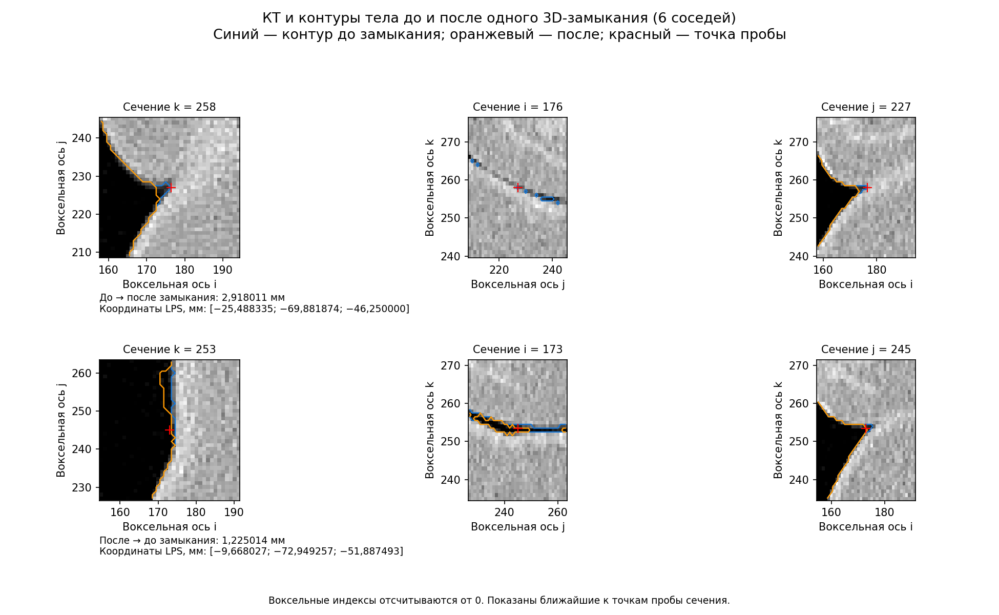

In [61]:
from IPython.display import display
display(body_correction_figure(report_data,include_js=False))

**Рисунок подготовки геометрии 1. Локальные сечения КТ.** Синие контуры — до замыкания, оранжевые — после; красные кресты — точки локальной пробы вершин. Верхний ряд — до → после, нижний — после → до. Показаны три ближайших воксельных сечения; плоскости могут не проходить точно через трёхмерную точку. Контуры сечений построены на уровне 0,5, измеренные поверхности — на уровне 0,49. Индексы отсчитываются от нуля; координаты — LPS, мм. Анатомическое принятие коррекции не заявляется.

До → после: выборочный максимум **2,329063922 мм**, локальные вершины **2,918010584 мм** в точке **[-25,488335; -69,881874; -46,250000] LPS мм**. После → до: выборочный максимум **1,130394967 мм**, локальный **1,225013733 мм** в точке **[-9,668027; -72,949257; -51,887493] LPS мм**. Самое сильное проверенное изменение связано с компонентой изменённых вокселей №97 при 26-соседней связности, рядом с вокселем [176, 227, 258]. Эта компонента содержит 396 добавленных вокселей в верхней части объёма КТ: её LPS-границы x -53,613328…58,007736 мм, y -74,707072…-65,039106 мм, z -53,750000…-21,250000 мм; это пространственная область, без анатомического диагноза. Это локализация по КТ, без анатомического принятия. Максимумы разных наборов проб не являются глобальным расстоянием Хаусдорфа. Замороженная FEM-геометрия при диагностике не изменялась.

## Происхождение и ограничения

In [62]:
from IPython.display import display
display(numbered_table(provenance_table(report_data),43))

Постановка,Сохранённые данные,Проверка происхождения
Прежняя постановка с 1×4,Исполненная конфигурация,Сохранено; реквизиты приведены в техническом паспорте
Прежняя постановка с 1×4,Неизменяемая исходная конфигурация,Сохранено; реквизиты приведены в техническом паспорте
Прежняя постановка с 1×4,Измеренные уровни,Сохранено; реквизиты приведены в техническом паспорте
Прежняя постановка с 1×4,Паспорт входных данных,Сохранено; реквизиты приведены в техническом паспорте
Прежняя постановка с 1×4,Начальное приближение,Сохранено; реквизиты приведены в техническом паспорте
Прежняя постановка с 1×4,Выбранный кандидат,Сохранено; реквизиты приведены в техническом паспорте
Прежняя постановка с 1×4,Начальный численный аудит,Сохранено; реквизиты приведены в техническом паспорте
Прежняя постановка с 1×4,Аудит выбранной точки,Сохранено; реквизиты приведены в техническом паспорте
Прежняя постановка с 1×4,Покрытие прежнего положения,Сохранено; реквизиты приведены в техническом паспорте
Прежняя постановка с 1×4,Итоговое покрытие контактов,Сохранено; реквизиты приведены в техническом паспорте


Входы прежнего расчёта остаются неизменными; изменяемые после расчёта программные файлы проверяются по сохранённым контрольным суммам и архивам точных исполненных байтов. Для исправленного расчёта проверяются собственные наблюдения и паспорт, опорные данные, параметры и координаты, планы моделей, подготовленные материалы и источники контрольных файлов. Исторические и новые выборки не переименовываются друг в друга. Исходная конфигурация, конфигурация остановленной попытки совместного поиска без предварительного профиля и фактическая конфигурация с приоритетом геометрии показываются раздельно.

Это отчёт о разработке методики. Ни завершение процедуры, ни качество сетки, ни малая невязка одной точки не устанавливают независимой валидации тканей, глобальной сеточной сходимости, идентифицируемости всех параметров или функций сердца. Технические границы 0,1–100 Ом·м сохранены; автоматического расширения нет. Дыхательная разметка, физическое возбуждение, влияние контактов и статическая геометрия для двух фаз остаются отдельными вопросами. Отрицательные контроли и неполные проверки сохраняются в выводах.